# Sleep Staging — 10: Fine-tuning end-to-end

**Objetivo:** evaluar si el modelo temporal mejora cuando la CNN también puede ajustar su representación durante el entrenamiento.

En NB8 y NB9 la CNN se mantuvo congelada y la BiGRU trabajó sobre embeddings calculados previamente. En esta notebook se conserva la ventana de **5 epochs** seleccionada en NB9, pero se entrenan de manera conjunta:

```text
señales → CNN → embeddings → BiGRU → etapa de sueño
```

El modelo parte de los pesos ya aprendidos en NB6 y NB9. De esta forma, el experimento mide el efecto del fine-tuning conjunto sin volver a entrenar la arquitectura desde cero.

---
## 1. Setup

Se reutilizan las señales procesadas, la normalización y el split por sujeto de las notebooks anteriores.

Para mantener una comparación directa con NB9, se usan los mismos epochs centrales empleados en la evaluación de contexto 3, 5 y 7. El tamaño de contexto queda fijo en 5 epochs.

In [2]:
from pathlib import Path
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

for directory in (RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Entradas
SIGNALS_PATH = DATA_DIR / "dl_signals.npy"
CACHE_META_PATH = DATA_DIR / "dl_metadata.parquet"
NORM_PATH = RESULTS_DIR / "dl_channel_normalization.json"
DL_SPLIT_PATH = RESULTS_DIR / "dl_subject_split.json"

CNN_MODEL_PATH = MODELS_DIR / "dl_cnn_baseline.pt"
TEMPORAL_MODEL_PATH = MODELS_DIR / "dl_context_5_bigru.pt"
NB9_TEST_SUMMARY_PATH = RESULTS_DIR / "dl_context_size_test.csv"

# Salidas
FINETUNED_MODEL_PATH = MODELS_DIR / "dl_end_to_end_finetuned.pt"
HISTORY_PATH = RESULTS_DIR / "dl_end_to_end_training_history.csv"
METRICS_PATH = RESULTS_DIR / "dl_end_to_end_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "dl_end_to_end_predictions.parquet"
COMPARISON_PATH = RESULTS_DIR / "dl_end_to_end_comparison.csv"
CLASS_COMPARISON_PATH = RESULTS_DIR / "dl_end_to_end_class_comparison.csv"
TRANSITION_COMPARISON_PATH = RESULTS_DIR / "dl_end_to_end_transition_comparison.csv"

HISTORY_FIG_PATH = FIGURES_DIR / "dl_end_to_end_training.png"
CM_PATH = FIGURES_DIR / "dl_end_to_end_confusion_matrix.png"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

CONTEXT_SIZE = 5
MAX_CONTEXT = 7
EMBEDDING_DIM = 128
HIDDEN_DIM = 64

BATCH_SIZE = 32
MAX_EPOCHS = 12
PATIENCE = 3
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Device:  {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU:     {torch.cuda.get_device_name(0)}")

PyTorch: 2.11.0+cu128
Device:  cuda
GPU:     NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
required_paths = [
    SIGNALS_PATH,
    CACHE_META_PATH,
    NORM_PATH,
    DL_SPLIT_PATH,
    CNN_MODEL_PATH,
    TEMPORAL_MODEL_PATH,
]

missing = [path for path in required_paths if not path.exists()]

if missing:
    raise FileNotFoundError(
        "Faltan artefactos necesarios. Ejecutá NB6 y NB9 antes de NB10:\n"
        + "\n".join(f"- {path}" for path in missing)
    )

signals = np.load(SIGNALS_PATH, mmap_mode="r")
metadata = pd.read_parquet(CACHE_META_PATH).reset_index(drop=True)

if len(signals) != len(metadata):
    raise ValueError("Señales y metadata tienen distinto número de epochs.")

with open(NORM_PATH, "r", encoding="utf-8") as file:
    norm_info = json.load(file)

channel_mean = np.asarray(
    norm_info["channel_mean_uv"],
    dtype=np.float32,
)
channel_std = np.asarray(
    norm_info["channel_std_uv"],
    dtype=np.float32,
)

with open(DL_SPLIT_PATH, "r", encoding="utf-8") as file:
    split_info = json.load(file)

train_subjects = set(split_info["train_subjects"])
val_subjects = set(split_info["validation_subjects"])
test_subjects = set(split_info["test_subjects"])

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

print(f"Señales:    {signals.shape}")
print(f"Epochs:     {len(metadata):,}")
print(f"Sujetos:    {metadata['subject'].nunique()}")
print(f"Train:      {len(train_subjects)} sujetos")
print(f"Validation: {len(val_subjects)} sujetos")
print(f"Test:       {len(test_subjects)} sujetos")

Señales:    (135471, 7, 3000)
Epochs:     135,471
Sujetos:    149
Train:      95 sujetos
Validation: 24 sujetos
Test:       30 sujetos


---
## 2. Índice temporal

Se reconstruye la ventana de 5 epochs con la misma lógica de NB8 y NB9.

Para conservar exactamente los centros usados en NB9, primero se identifican los epochs que admiten una ventana válida de 7 epochs y luego se toma, sobre esos mismos centros, la ventana de 5 epochs.

Esto evita que una diferencia en las muestras evaluadas se confunda con el efecto del fine-tuning.

In [4]:
def build_temporal_index(metadata, context_size):
    half = context_size // 2
    rows = []

    for subject, subject_df in metadata.groupby("subject", sort=True):
        subject_df = (
            subject_df
            .sort_values("epoch_global")
            .reset_index(drop=True)
        )

        global_idx = subject_df["epoch_global"].to_numpy(dtype=np.int64)
        source_idx = subject_df["source_epoch_index"].to_numpy(dtype=np.int64)
        onset = subject_df["recording_onset_s"].to_numpy(dtype=np.float64)
        labels = subject_df["label"].to_numpy(dtype=np.int64)

        for center in range(half, len(subject_df) - half):
            start = center - half
            stop = center + half + 1

            source_window = source_idx[start:stop]
            onset_window = onset[start:stop]

            if not np.all(np.diff(source_window) == 1):
                continue

            if not np.allclose(
                np.diff(onset_window),
                30.0,
                atol=1e-3,
            ):
                continue

            rows.append({
                "subject": subject,
                "source_epoch_index": int(source_idx[center]),
                "center_epoch_global": int(global_idx[center]),
                "recording_onset_s": float(onset[center]),
                "label": int(labels[center]),
                "sequence_indices": global_idx[start:stop].tolist(),
                "is_transition": bool(
                    labels[center - 1] != labels[center]
                    or labels[center + 1] != labels[center]
                ),
            })

    return pd.DataFrame(rows)


index_5 = build_temporal_index(metadata, CONTEXT_SIZE)
index_7 = build_temporal_index(metadata, MAX_CONTEXT)

join_cols = ["subject", "source_epoch_index"]

common_keys = index_7[join_cols].copy()

temporal_index = common_keys.merge(
    index_5,
    on=join_cols,
    how="left",
    validate="one_to_one",
)

if temporal_index["sequence_indices"].isna().any():
    raise ValueError("Hay centros comunes sin una ventana válida de 5 epochs.")

print(f"Secuencias utilizadas: {len(temporal_index):,}")
print(f"Sujetos:               {temporal_index['subject'].nunique()}")

Secuencias utilizadas: 134,564
Sujetos:               149


In [5]:
def partition_index(index_df, subjects):
    return index_df[
        index_df["subject"].isin(subjects)
    ].reset_index(drop=True)


train_index = partition_index(temporal_index, train_subjects)
val_index = partition_index(temporal_index, val_subjects)
test_index = partition_index(temporal_index, test_subjects)

sequence_summary = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "subjects": [
        train_index["subject"].nunique(),
        val_index["subject"].nunique(),
        test_index["subject"].nunique(),
    ],
    "sequences": [
        len(train_index),
        len(val_index),
        len(test_index),
    ],
})

display(sequence_summary)

if NB9_TEST_SUMMARY_PATH.exists():
    nb9_test = pd.read_csv(NB9_TEST_SUMMARY_PATH)
    display(
        nb9_test.loc[
            nb9_test["context_size"] == CONTEXT_SIZE
        ].round(4)
    )

,partition,subjects,sequences
0,train,95,86730
1,validation,24,21388
2,test,30,26446


,context_size,seconds,accuracy,balanced_accuracy,macro_f1,n_epochs
1,5,150,0.7833,0.7804,0.7673,26446


---
## 3. Dataset de secuencias

A diferencia de NB8 y NB9, acá no se leen embeddings precalculados. Cada ejemplo contiene las cinco señales completas que forman la secuencia.

La normalización por canal es la misma utilizada para entrenar la CNN original. La entrada de cada batch tiene forma:

```text
(batch, 5, 7, 3000)
```

In [6]:
class TemporalSignalDataset(Dataset):
    def __init__(self, signals, index_df, mean, std):
        self.signals = signals

        self.sequence_indices = np.stack(
            index_df["sequence_indices"]
            .apply(np.asarray)
            .to_numpy()
        ).astype(np.int64)

        self.labels = index_df[
            "label"
        ].to_numpy(dtype=np.int64)

        self.mean = np.asarray(
            mean,
            dtype=np.float32,
        )[None, :, None]

        self.std = np.asarray(
            std,
            dtype=np.float32,
        )[None, :, None]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, item):
        indices = self.sequence_indices[item]

        x = np.asarray(
            self.signals[indices],
            dtype=np.float32,
        )

        x = (x - self.mean) / self.std
        y = self.labels[item]

        return (
            torch.from_numpy(x),
            torch.tensor(y, dtype=torch.long),
        )


train_dataset = TemporalSignalDataset(
    signals,
    train_index,
    channel_mean,
    channel_std,
)

val_dataset = TemporalSignalDataset(
    signals,
    val_index,
    channel_mean,
    channel_std,
)

test_dataset = TemporalSignalDataset(
    signals,
    test_index,
    channel_mean,
    channel_std,
)

generator = torch.Generator()
generator.manual_seed(RANDOM_STATE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print(f"Batch size:  {BATCH_SIZE}")
print(f"Train:      {len(train_dataset):,} secuencias")
print(f"Validation: {len(val_dataset):,} secuencias")
print(f"Test:       {len(test_dataset):,} secuencias")

Batch size:  32
Train:      86,730 secuencias
Validation: 21,388 secuencias
Test:       26,446 secuencias


---
## 4. Modelo end-to-end

Se reconstruyen la CNN de NB6 y la BiGRU utilizada con contexto 5 en NB9.

Primero se cargan sus pesos por separado. Luego ambos bloques se combinan en un único modelo. La CNN procesa cada epoch de la secuencia y la BiGRU recibe los cinco embeddings resultantes.

Todos los parámetros quedan entrenables.

In [7]:
class SleepCNN(nn.Module):
    def __init__(self, n_channels=7, n_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, n_classes),
        )

    def encode(self, x):
        return self.features(x).squeeze(-1)

    def forward(self, x):
        return self.classifier(self.features(x))


class TemporalBiGRU(nn.Module):
    def __init__(self, input_dim=128, hidden_dim=64, n_classes=5):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )

        self.dropout = nn.Dropout(0.30)
        self.classifier = nn.Linear(
            hidden_dim * 2,
            n_classes,
        )

    def forward(self, x):
        sequence_output, _ = self.gru(x)
        center = x.shape[1] // 2
        center_output = sequence_output[:, center, :]

        return self.classifier(
            self.dropout(center_output)
        )

In [8]:
cnn = SleepCNN(
    n_channels=signals.shape[1],
    n_classes=len(STAGE_NAMES),
)

cnn.load_state_dict(
    torch.load(
        CNN_MODEL_PATH,
        map_location="cpu",
    )
)

temporal_head = TemporalBiGRU(
    input_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    n_classes=len(STAGE_NAMES),
)

temporal_head.load_state_dict(
    torch.load(
        TEMPORAL_MODEL_PATH,
        map_location="cpu",
    )
)


class EndToEndSleepModel(nn.Module):
    def __init__(self, cnn, temporal_head):
        super().__init__()

        self.encoder = cnn.features
        self.gru = temporal_head.gru
        self.dropout = temporal_head.dropout
        self.classifier = temporal_head.classifier

    def forward(self, x):
        batch_size, context_size, n_channels, n_samples = x.shape

        x = x.reshape(
            batch_size * context_size,
            n_channels,
            n_samples,
        )

        embeddings = self.encoder(x).squeeze(-1)

        embeddings = embeddings.reshape(
            batch_size,
            context_size,
            -1,
        )

        sequence_output, _ = self.gru(embeddings)

        center = context_size // 2
        center_output = sequence_output[:, center, :]

        return self.classifier(
            self.dropout(center_output)
        )


model = EndToEndSleepModel(
    cnn,
    temporal_head,
).to(DEVICE)

for parameter in model.parameters():
    parameter.requires_grad = True

n_parameters = sum(p.numel() for p in model.parameters())
n_trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)
print(f"Parámetros totales:      {n_parameters:,}")
print(f"Parámetros entrenables:  {n_trainable:,}")

EndToEndSleepModel(
  (encoder): Sequential(
    (0): Conv1d(7, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (gru): GRU(128, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=5, bias=True)
)
Parámetros totales:      132,677
Parámetros 

---
## 5. Baseline antes del fine-tuning

Antes de actualizar los pesos se evalúa el modelo combinado tal como fue inicializado.

Este resultado debería quedar muy cerca del modelo de contexto 5 de NB9. Sirve como referencia directa para medir cuánto aporta el ajuste conjunto.

In [9]:
def predict_loader(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    probabilities = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(
                DEVICE,
                non_blocking=True,
            )

            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            pred = probs.argmax(dim=1)

            y_true.append(yb.numpy())
            y_pred.append(pred.cpu().numpy())
            probabilities.append(
                probs.cpu().numpy()
            )

    return (
        np.concatenate(y_true),
        np.concatenate(y_pred),
        np.concatenate(probabilities),
    )


def evaluate_loader(model, loader):
    y_true, y_pred, _ = predict_loader(
        model,
        loader,
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),
    }


baseline_val_metrics = evaluate_loader(
    model,
    val_loader,
)

baseline_y_true, baseline_y_pred, baseline_y_prob = predict_loader(
    model,
    test_loader,
)

baseline_test_metrics = {
    "accuracy": accuracy_score(
        baseline_y_true,
        baseline_y_pred,
    ),
    "balanced_accuracy": balanced_accuracy_score(
        baseline_y_true,
        baseline_y_pred,
    ),
    "macro_f1": f1_score(
        baseline_y_true,
        baseline_y_pred,
        average="macro",
    ),
}

print("Validation:")
print(
    {
        key: round(value, 4)
        for key, value in baseline_val_metrics.items()
    }
)

print("\nTest:")
print(
    {
        key: round(value, 4)
        for key, value in baseline_test_metrics.items()
    }
)

Validation:
{'accuracy': 0.7952, 'balanced_accuracy': 0.7917, 'macro_f1': 0.7816}

Test:
{'accuracy': 0.7833, 'balanced_accuracy': 0.7804, 'macro_f1': 0.7673}


---
## 6. Fine-tuning

El modelo completo se entrena con un learning rate bajo porque tanto la CNN como la BiGRU parten de pesos ya ajustados.

Se mantienen los pesos de clase y el criterio de selección utilizado anteriormente: el mejor checkpoint se guarda según Macro-F1 de validation.

In [10]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.asarray(STAGE_ORDER),
    y=train_index["label"].to_numpy(),
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

weights_df = pd.DataFrame({
    "stage": STAGE_NAMES,
    "weight": class_weights.cpu().numpy(),
})

display(weights_df.round(3))

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print(f"Learning rate: {LEARNING_RATE}")
print(f"Máximo de epochs: {MAX_EPOCHS}")
print(f"Patience: {PATIENCE}")

,stage,weight
0,W,1.139
1,N1,1.812
2,N2,0.548
3,N3,1.036
4,REM,1.282


Learning rate: 0.0001
Máximo de epochs: 12
Patience: 3


In [11]:
history = []
best_macro_f1 = -np.inf
best_epoch = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()

    running_loss = 0.0
    n_train = 0

    for xb, yb in train_loader:
        xb = xb.to(
            DEVICE,
            non_blocking=True,
        )
        yb = yb.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)
        n_train += len(yb)

    train_loss = running_loss / n_train
    val_metrics = evaluate_loader(
        model,
        val_loader,
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={train_loss:.4f} | "
        f"val Macro-F1={val_metrics['macro_f1']:.4f} | "
        f"val BalAcc={val_metrics['balanced_accuracy']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            FINETUNED_MODEL_PATH,
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

history = pd.DataFrame(history)
history.to_csv(
    HISTORY_PATH,
    index=False,
)

model.load_state_dict(
    torch.load(
        FINETUNED_MODEL_PATH,
        map_location=DEVICE,
    )
)

print(f"\nMejor epoch: {best_epoch}")
print(f"Mejor val Macro-F1: {best_macro_f1:.4f}")

display(history.round(4))

Epoch 01 | loss=0.4015 | val Macro-F1=0.7783 | val BalAcc=0.7890
Epoch 02 | loss=0.3890 | val Macro-F1=0.7765 | val BalAcc=0.7895
Epoch 03 | loss=0.3821 | val Macro-F1=0.7738 | val BalAcc=0.7860
Epoch 04 | loss=0.3782 | val Macro-F1=0.7757 | val BalAcc=0.7834
Early stopping.

Mejor epoch: 1
Mejor val Macro-F1: 0.7783


,epoch,train_loss,val_accuracy,val_balanced_accuracy,val_macro_f1
0,1,0.4015,0.7939,0.7890,0.7783
1,2,0.3890,0.7900,0.7895,0.7765
2,3,0.3821,0.7876,0.7860,0.7738
3,4,0.3782,0.7964,0.7834,0.7757


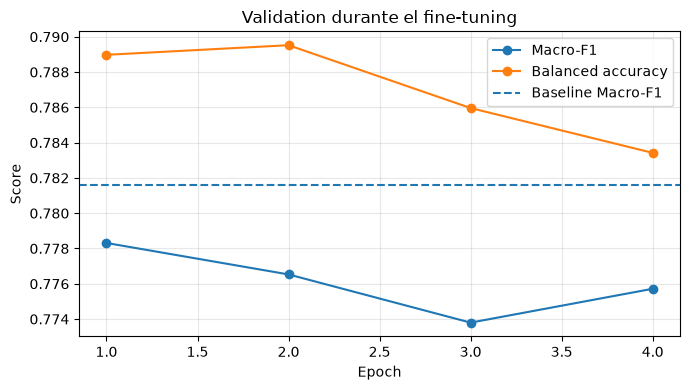

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    history["epoch"],
    history["val_macro_f1"],
    marker="o",
    label="Macro-F1",
)

ax.plot(
    history["epoch"],
    history["val_balanced_accuracy"],
    marker="o",
    label="Balanced accuracy",
)

ax.axhline(
    baseline_val_metrics["macro_f1"],
    linestyle="--",
    label="Baseline Macro-F1",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Validation durante el fine-tuning")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(
    HISTORY_FIG_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.show()

---
## 7. Evaluación sobre test

Se evalúa el mejor checkpoint seleccionado con validation.

La comparación principal es contra el mismo modelo antes del fine-tuning. Ambos usan la misma ventana de 5 epochs y exactamente los mismos ejemplos de test.

In [13]:
y_true, y_pred, y_prob = predict_loader(
    model,
    test_loader,
)

finetuned_metrics = {
    "accuracy": float(
        accuracy_score(y_true, y_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "macro_f1": float(
        f1_score(
            y_true,
            y_pred,
            average="macro",
        )
    ),
    "n_test_sequences": int(len(y_true)),
    "n_test_subjects": int(
        test_index["subject"].nunique()
    ),
    "context_size": CONTEXT_SIZE,
    "best_epoch": int(best_epoch),
}

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        finetuned_metrics,
        file,
        indent=2,
    )

print(json.dumps(
    finetuned_metrics,
    indent=2,
))

print()

print(
    classification_report(
        y_true,
        y_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)

{
  "accuracy": 0.7848067760719958,
  "balanced_accuracy": 0.7840486173217889,
  "macro_f1": 0.7689779847694622,
  "n_test_sequences": 26446,
  "n_test_subjects": 30,
  "context_size": 5,
  "best_epoch": 1
}

              precision    recall  f1-score   support

           W     0.8502    0.7943    0.8213      4210
          N1     0.4445    0.5946    0.5087      3024
          N2     0.8724    0.7386    0.8000     10157
          N3     0.8225    0.8905    0.8551      5012
         REM     0.8211    0.9023    0.8598      4043

    accuracy                         0.7848     26446
   macro avg     0.7622    0.7840    0.7690     26446
weighted avg     0.8027    0.7848    0.7897     26446



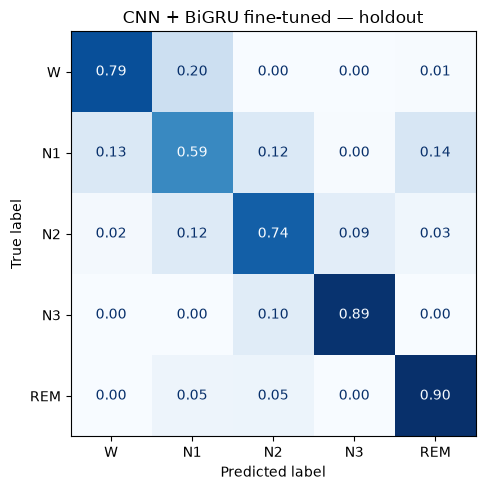

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("CNN + BiGRU fine-tuned — holdout")

plt.tight_layout()

fig.savefig(
    CM_PATH,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [15]:
predictions = test_index[
    [
        "subject",
        "center_epoch_global",
        "source_epoch_index",
        "recording_onset_s",
        "is_transition",
        "label",
    ]
].copy()

predictions = predictions.rename(
    columns={"label": "y_true"}
)

predictions["y_pred_baseline"] = baseline_y_pred
predictions["y_pred_finetuned"] = y_pred

for class_idx, stage_name in STAGE_MAP.items():
    predictions[
        f"prob_{stage_name}"
    ] = y_prob[:, class_idx]

predictions.to_parquet(
    PREDICTIONS_PATH,
    index=False,
)

display(predictions.head())

,subject,center_epoch_global,source_epoch_index,recording_onset_s,is_transition,y_true,y_pred_baseline,y_pred_finetuned,prob_W,prob_N1,prob_N2,prob_N3,prob_REM
0,SN010,8290,3,90.0,False,0,0,0,0.995460,0.004366,0.000056,0.000004,0.000115
1,SN010,8291,4,120.0,False,0,0,0,0.980428,0.018827,0.000137,0.000005,0.000603
2,SN010,8292,5,150.0,False,0,0,0,0.995638,0.003722,0.000050,0.000002,0.000587
3,SN010,8293,6,180.0,False,0,0,0,0.994133,0.005288,0.000048,0.000003,0.000528
4,SN010,8294,7,210.0,False,0,0,0,0.993645,0.005681,0.000045,0.000003,0.000625


---
## 8. Comparación con el modelo congelado

Primero se comparan las métricas globales antes y después del fine-tuning.

Después se revisa el cambio por etapa de sueño y según la cercanía a una transición.

In [16]:
comparison = pd.DataFrame([
    {
        "model": "CNN + BiGRU congelado",
        "accuracy": baseline_test_metrics["accuracy"],
        "balanced_accuracy": baseline_test_metrics[
            "balanced_accuracy"
        ],
        "macro_f1": baseline_test_metrics["macro_f1"],
        "n_epochs": len(baseline_y_true),
    },
    {
        "model": "CNN + BiGRU fine-tuned",
        "accuracy": finetuned_metrics["accuracy"],
        "balanced_accuracy": finetuned_metrics[
            "balanced_accuracy"
        ],
        "macro_f1": finetuned_metrics["macro_f1"],
        "n_epochs": len(y_true),
    },
])

comparison.to_csv(
    COMPARISON_PATH,
    index=False,
)

display(comparison.round(4))

delta_macro_f1 = (
    finetuned_metrics["macro_f1"]
    - baseline_test_metrics["macro_f1"]
)

print(
    f"Cambio de Macro-F1: "
    f"{delta_macro_f1:+.4f}"
)

,model,accuracy,balanced_accuracy,macro_f1,n_epochs
0,CNN + BiGRU congelado,0.7833,0.7804,0.7673,26446
1,CNN + BiGRU fine-tuned,0.7848,0.7840,0.7690,26446


Cambio de Macro-F1: +0.0016


In [17]:
class_rows = []

for class_idx, stage_name in STAGE_MAP.items():
    baseline_f1 = f1_score(
        baseline_y_true == class_idx,
        baseline_y_pred == class_idx,
        zero_division=0,
    )

    finetuned_f1 = f1_score(
        y_true == class_idx,
        y_pred == class_idx,
        zero_division=0,
    )

    class_rows.append({
        "stage": stage_name,
        "baseline_f1": baseline_f1,
        "finetuned_f1": finetuned_f1,
        "delta_f1": finetuned_f1 - baseline_f1,
        "support": int(
            (y_true == class_idx).sum()
        ),
    })

class_comparison = pd.DataFrame(
    class_rows
)

class_comparison.to_csv(
    CLASS_COMPARISON_PATH,
    index=False,
)

display(
    class_comparison.round(4)
)

,stage,baseline_f1,finetuned_f1,delta_f1,support
0,W,0.8010,0.8213,0.0203,4210
1,N1,0.5147,0.5087,-0.0060,3024
2,N2,0.8058,0.8000,-0.0059,10157
3,N3,0.8501,0.8551,0.0050,5012
4,REM,0.8651,0.8598,-0.0053,4043


In [18]:
transition_rows = []

comparison_predictions = test_index[
    [
        "is_transition",
        "label",
    ]
].copy()

comparison_predictions = comparison_predictions.rename(
    columns={"label": "y_true"}
)

comparison_predictions[
    "y_pred_baseline"
] = baseline_y_pred

comparison_predictions[
    "y_pred_finetuned"
] = y_pred

for subset_name, mask in [
    (
        "stable",
        ~comparison_predictions[
            "is_transition"
        ].astype(bool),
    ),
    (
        "transition",
        comparison_predictions[
            "is_transition"
        ].astype(bool),
    ),
]:
    subset = comparison_predictions.loc[mask]

    for model_name, pred_col in [
        (
            "CNN + BiGRU congelado",
            "y_pred_baseline",
        ),
        (
            "CNN + BiGRU fine-tuned",
            "y_pred_finetuned",
        ),
    ]:
        transition_rows.append({
            "subset": subset_name,
            "model": model_name,
            "n_epochs": len(subset),
            "accuracy": accuracy_score(
                subset["y_true"],
                subset[pred_col],
            ),
            "balanced_accuracy": balanced_accuracy_score(
                subset["y_true"],
                subset[pred_col],
            ),
            "macro_f1": f1_score(
                subset["y_true"],
                subset[pred_col],
                average="macro",
            ),
        })

transition_comparison = pd.DataFrame(
    transition_rows
)

transition_comparison.to_csv(
    TRANSITION_COMPARISON_PATH,
    index=False,
)

display(
    transition_comparison.round(4)
)

,subset,model,n_epochs,accuracy,balanced_accuracy,macro_f1
0,stable,CNN + BiGRU congelado,19400,0.8432,0.8102,0.7768
1,stable,CNN + BiGRU fine-tuned,19400,0.8469,0.8121,0.7801
2,transition,CNN + BiGRU congelado,7046,0.6181,0.6326,0.6191
3,transition,CNN + BiGRU fine-tuned,7046,0.6140,0.6412,0.6200


---
## 9. Conclusiones

El fine-tuning conjunto de la CNN y la BiGRU no produjo una mejora clara respecto del modelo con la CNN congelada. En validation, el mejor Macro-F1 fue de 0.7783, por debajo del 0.7816 obtenido antes del ajuste. En test hubo una mejora pequeña, de 0.7673 a 0.7690, pero no alcanza para justificar el cambio según el criterio de selección utilizado.

Durante el entrenamiento, la pérdida siguió bajando, mientras que el Macro-F1 de validation no mejoró después de la primera epoch. El entrenamiento se detuvo en la cuarta epoch por early stopping.

El cambio tampoco benefició a todas las etapas. W presentó la mayor mejora de F1 y N3 mejoró levemente, mientras que N1, N2 y REM bajaron. N1 continúa siendo la etapa más difícil. En los epochs cercanos a transiciones, el Macro-F1 prácticamente no cambió, por lo que el ajuste no resolvió la dificultad observada en las notebooks anteriores.

Con esta configuración, se conserva la CNN congelada con BiGRU y una ventana de 5 epochs. El fine-tuning probado no aportó una mejora en validation que justifique sumar esta etapa de entrenamiento.